# COMP813 — TF-IDF Feature Ablation

## Objective

Investigate whether incorporating bigram features into TF-IDF
improves phishing/spam email classification and cross-dataset
generalisation.

Two TF-IDF configurations are compared:

1. Unigrams only
2. Unigrams + bigrams

Both configurations are evaluated using:

- Logistic Regression
- Linear SVM

Evaluation is performed on both the held-out Enron test set and
the unseen CEAS-08 dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [5]:
train_df = pd.read_csv(
    "enron_train.csv"
)

val_df = pd.read_csv(
    "enron_val.csv"
)

test_df = pd.read_csv(
    "enron_test.csv"
)

ceas_df = pd.read_csv(
    "ceas08_clean.csv"
)

print("Enron train:", train_df.shape)
print("Enron validation:", val_df.shape)
print("Enron test:", test_df.shape)
print("CEAS-08:", ceas_df.shape)

Enron train: (20596, 2)
Enron validation: (4414, 2)
Enron test: (4414, 2)
CEAS-08: (38964, 2)


In [7]:
X_train = train_df["text"].astype(str)
y_train = train_df["label"]

X_val = val_df["text"].astype(str)
y_val = val_df["label"]

X_test = test_df["text"].astype(str)
y_test = test_df["label"]

X_ceas = ceas_df["text"].astype(str)
y_ceas = ceas_df["label"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))
print("CEAS samples:", len(X_ceas))

Training samples: 20596
Validation samples: 4414
Test samples: 4414
CEAS samples: 38964


In [8]:
MAX_FEATURES = 100000

tfidf_unigram = TfidfVectorizer(
    ngram_range=(1, 1),
    max_features=MAX_FEATURES,
    lowercase=True,
    sublinear_tf=True
)

X_train_uni = tfidf_unigram.fit_transform(
    X_train
)

X_val_uni = tfidf_unigram.transform(
    X_val
)

X_test_uni = tfidf_unigram.transform(
    X_test
)

X_ceas_uni = tfidf_unigram.transform(
    X_ceas
)

print("Unigram TF-IDF")
print("Training:", X_train_uni.shape)
print("Validation:", X_val_uni.shape)
print("Test:", X_test_uni.shape)
print("CEAS:", X_ceas_uni.shape)

Unigram TF-IDF
Training: (20596, 100000)
Validation: (4414, 100000)
Test: (4414, 100000)
CEAS: (38964, 100000)


In [9]:
lr_uni = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

start_time = time.time()

lr_uni.fit(
    X_train_uni,
    y_train
)

lr_uni_training_time = time.time() - start_time

print(
    f"Logistic Regression training time: "
    f"{lr_uni_training_time:.2f} seconds"
)

Logistic Regression training time: 1.92 seconds


In [10]:
lr_uni_enron_pred = lr_uni.predict(X_test_uni)
lr_uni_ceas_pred = lr_uni.predict(X_ceas_uni)


# Enron
lr_uni_enron_accuracy = accuracy_score(
    y_test,
    lr_uni_enron_pred
)

lr_uni_enron_precision = precision_score(
    y_test,
    lr_uni_enron_pred
)

lr_uni_enron_recall = recall_score(
    y_test,
    lr_uni_enron_pred
)

lr_uni_enron_f1 = f1_score(
    y_test,
    lr_uni_enron_pred
)


# CEAS-08
lr_uni_ceas_accuracy = accuracy_score(
    y_ceas,
    lr_uni_ceas_pred
)

lr_uni_ceas_precision = precision_score(
    y_ceas,
    lr_uni_ceas_pred
)

lr_uni_ceas_recall = recall_score(
    y_ceas,
    lr_uni_ceas_pred
)

lr_uni_ceas_f1 = f1_score(
    y_ceas,
    lr_uni_ceas_pred
)


print("LOGISTIC REGRESSION — UNIGRAM")
print("=" * 60)

print("\nENRON TEST")
print(f"Accuracy : {lr_uni_enron_accuracy:.4f}")
print(f"Precision: {lr_uni_enron_precision:.4f}")
print(f"Recall   : {lr_uni_enron_recall:.4f}")
print(f"F1 Score : {lr_uni_enron_f1:.4f}")

print("\nCEAS-08")
print(f"Accuracy : {lr_uni_ceas_accuracy:.4f}")
print(f"Precision: {lr_uni_ceas_precision:.4f}")
print(f"Recall   : {lr_uni_ceas_recall:.4f}")
print(f"F1 Score : {lr_uni_ceas_f1:.4f}")

LOGISTIC REGRESSION — UNIGRAM

ENRON TEST
Accuracy : 0.9839
Precision: 0.9733
Recall   : 0.9933
F1 Score : 0.9832

CEAS-08
Accuracy : 0.7160
Precision: 0.6627
Recall   : 0.9965
F1 Score : 0.7961


In [11]:
print("LOGISTIC REGRESSION — ENRON")
print(
    classification_report(
        y_test,
        lr_uni_enron_pred,
        target_names=[
            "Legitimate",
            "Phishing/Spam"
        ]
    )
)

print("\nLOGISTIC REGRESSION — CEAS-08")
print(
    classification_report(
        y_ceas,
        lr_uni_ceas_pred,
        target_names=[
            "Legitimate",
            "Phishing/Spam"
        ]
    )
)

LOGISTIC REGRESSION — ENRON
               precision    recall  f1-score   support

   Legitimate       0.99      0.98      0.98      2322
Phishing/Spam       0.97      0.99      0.98      2092

     accuracy                           0.98      4414
    macro avg       0.98      0.98      0.98      4414
 weighted avg       0.98      0.98      0.98      4414


LOGISTIC REGRESSION — CEAS-08
               precision    recall  f1-score   support

   Legitimate       0.99      0.36      0.53     17290
Phishing/Spam       0.66      1.00      0.80     21674

     accuracy                           0.72     38964
    macro avg       0.83      0.68      0.66     38964
 weighted avg       0.81      0.72      0.68     38964



In [13]:
svm_uni = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42
)

start_time = time.time()

svm_uni.fit(
    X_train_uni,
    y_train
)

svm_uni_training_time = time.time() - start_time

print(
    f"Linear SVM training time: "
    f"{svm_uni_training_time:.2f} seconds"
)

Linear SVM training time: 0.48 seconds


In [14]:
svm_uni_enron_pred = svm_uni.predict(X_test_uni)
svm_uni_ceas_pred = svm_uni.predict(X_ceas_uni)


# Enron
svm_uni_enron_accuracy = accuracy_score(
    y_test,
    svm_uni_enron_pred
)

svm_uni_enron_precision = precision_score(
    y_test,
    svm_uni_enron_pred
)

svm_uni_enron_recall = recall_score(
    y_test,
    svm_uni_enron_pred
)

svm_uni_enron_f1 = f1_score(
    y_test,
    svm_uni_enron_pred
)


# CEAS-08
svm_uni_ceas_accuracy = accuracy_score(
    y_ceas,
    svm_uni_ceas_pred
)

svm_uni_ceas_precision = precision_score(
    y_ceas,
    svm_uni_ceas_pred
)

svm_uni_ceas_recall = recall_score(
    y_ceas,
    svm_uni_ceas_pred
)

svm_uni_ceas_f1 = f1_score(
    y_ceas,
    svm_uni_ceas_pred
)


print("LINEAR SVM — UNIGRAM")
print("=" * 60)

print("\nENRON TEST")
print(f"Accuracy : {svm_uni_enron_accuracy:.4f}")
print(f"Precision: {svm_uni_enron_precision:.4f}")
print(f"Recall   : {svm_uni_enron_recall:.4f}")
print(f"F1 Score : {svm_uni_enron_f1:.4f}")

print("\nCEAS-08")
print(f"Accuracy : {svm_uni_ceas_accuracy:.4f}")
print(f"Precision: {svm_uni_ceas_precision:.4f}")
print(f"Recall   : {svm_uni_ceas_recall:.4f}")
print(f"F1 Score : {svm_uni_ceas_f1:.4f}")

LINEAR SVM — UNIGRAM

ENRON TEST
Accuracy : 0.9898
Precision: 0.9867
Recall   : 0.9919
F1 Score : 0.9893

CEAS-08
Accuracy : 0.7272
Precision: 0.6725
Recall   : 0.9933
F1 Score : 0.8020


In [15]:
tfidf_bigram = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=100000,
    lowercase=True,
    sublinear_tf=True
)

X_train_bi = tfidf_bigram.fit_transform(
    X_train
)

X_val_bi = tfidf_bigram.transform(
    X_val
)

X_test_bi = tfidf_bigram.transform(
    X_test
)

X_ceas_bi = tfidf_bigram.transform(
    X_ceas
)

print("Unigram + Bigram TF-IDF")
print("Training:", X_train_bi.shape)
print("Validation:", X_val_bi.shape)
print("Test:", X_test_bi.shape)
print("CEAS:", X_ceas_bi.shape)

Unigram + Bigram TF-IDF
Training: (20596, 100000)
Validation: (4414, 100000)
Test: (4414, 100000)
CEAS: (38964, 100000)


In [16]:
lr_bi = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

start_time = time.time()

lr_bi.fit(
    X_train_bi,
    y_train
)

lr_bi_training_time = time.time() - start_time

print(
    f"Logistic Regression training time: "
    f"{lr_bi_training_time:.2f} seconds"
)

Logistic Regression training time: 2.37 seconds


In [18]:
lr_bi_enron_pred = lr_bi.predict(X_test_bi)
lr_bi_ceas_pred = lr_bi.predict(X_ceas_bi)


# Enron
lr_bi_enron_accuracy = accuracy_score(
    y_test,
    lr_bi_enron_pred
)

lr_bi_enron_precision = precision_score(
    y_test,
    lr_bi_enron_pred
)

lr_bi_enron_recall = recall_score(
    y_test,
    lr_bi_enron_pred
)

lr_bi_enron_f1 = f1_score(
    y_test,
    lr_bi_enron_pred
)


# CEAS-08
lr_bi_ceas_accuracy = accuracy_score(
    y_ceas,
    lr_bi_ceas_pred
)

lr_bi_ceas_precision = precision_score(
    y_ceas,
    lr_bi_ceas_pred
)

lr_bi_ceas_recall = recall_score(
    y_ceas,
    lr_bi_ceas_pred
)

lr_bi_ceas_f1 = f1_score(
    y_ceas,
    lr_bi_ceas_pred
)


print("LOGISTIC REGRESSION — UNIGRAM + BIGRAM")
print("=" * 60)

print("\nENRON TEST")
print(f"Accuracy : {lr_bi_enron_accuracy:.4f}")
print(f"Precision: {lr_bi_enron_precision:.4f}")
print(f"Recall   : {lr_bi_enron_recall:.4f}")
print(f"F1 Score : {lr_bi_enron_f1:.4f}")

print("\nCEAS-08")
print(f"Accuracy : {lr_bi_ceas_accuracy:.4f}")
print(f"Precision: {lr_bi_ceas_precision:.4f}")
print(f"Recall   : {lr_bi_ceas_recall:.4f}")
print(f"F1 Score : {lr_bi_ceas_f1:.4f}")

LOGISTIC REGRESSION — UNIGRAM + BIGRAM

ENRON TEST
Accuracy : 0.9873
Precision: 0.9784
Recall   : 0.9952
F1 Score : 0.9867

CEAS-08
Accuracy : 0.7477
Precision: 0.6888
Recall   : 0.9967
F1 Score : 0.8147


In [19]:
svm_bi = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42
)

start_time = time.time()

svm_bi.fit(
    X_train_bi,
    y_train
)

svm_bi_training_time = time.time() - start_time

print(
    f"Linear SVM training time: "
    f"{svm_bi_training_time:.2f} seconds"
)

Linear SVM training time: 0.93 seconds


In [20]:
svm_bi_enron_pred = svm_bi.predict(X_test_bi)
svm_bi_ceas_pred = svm_bi.predict(X_ceas_bi)


# Enron
svm_bi_enron_accuracy = accuracy_score(
    y_test,
    svm_bi_enron_pred
)

svm_bi_enron_precision = precision_score(
    y_test,
    svm_bi_enron_pred
)

svm_bi_enron_recall = recall_score(
    y_test,
    svm_bi_enron_pred
)

svm_bi_enron_f1 = f1_score(
    y_test,
    svm_bi_enron_pred
)


# CEAS-08
svm_bi_ceas_accuracy = accuracy_score(
    y_ceas,
    svm_bi_ceas_pred
)

svm_bi_ceas_precision = precision_score(
    y_ceas,
    svm_bi_ceas_pred
)

svm_bi_ceas_recall = recall_score(
    y_ceas,
    svm_bi_ceas_pred
)

svm_bi_ceas_f1 = f1_score(
    y_ceas,
    svm_bi_ceas_pred
)


print("LINEAR SVM — UNIGRAM + BIGRAM")
print("=" * 60)

print("\nENRON TEST")
print(f"Accuracy : {svm_bi_enron_accuracy:.4f}")
print(f"Precision: {svm_bi_enron_precision:.4f}")
print(f"Recall   : {svm_bi_enron_recall:.4f}")
print(f"F1 Score : {svm_bi_enron_f1:.4f}")

print("\nCEAS-08")
print(f"Accuracy : {svm_bi_ceas_accuracy:.4f}")
print(f"Precision: {svm_bi_ceas_precision:.4f}")
print(f"Recall   : {svm_bi_ceas_recall:.4f}")
print(f"F1 Score : {svm_bi_ceas_f1:.4f}")

LINEAR SVM — UNIGRAM + BIGRAM

ENRON TEST
Accuracy : 0.9923
Precision: 0.9881
Recall   : 0.9957
F1 Score : 0.9919

CEAS-08
Accuracy : 0.7521
Precision: 0.6933
Recall   : 0.9943
F1 Score : 0.8169


In [21]:
ablation_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression",
        "Linear SVM",
        "Linear SVM"
    ],

    "Features": [
        "Unigram",
        "Unigram + Bigram",
        "Unigram",
        "Unigram + Bigram"
    ],

    "Enron F1": [
        lr_uni_enron_f1,
        lr_bi_enron_f1,
        svm_uni_enron_f1,
        svm_bi_enron_f1
    ],

    "CEAS-08 F1": [
        lr_uni_ceas_f1,
        lr_bi_ceas_f1,
        svm_uni_ceas_f1,
        svm_bi_ceas_f1
    ]
})

ablation_results["CEAS F1 Change"] = (
    ablation_results
    .groupby("Model")["CEAS-08 F1"]
    .transform(lambda x: x - x.iloc[0])
)

ablation_results

,Model,Features,Enron F1,CEAS-08 F1,CEAS F1 Change
0,Logistic Regression,Unigram,0.983203,0.796056,0.000000
1,Logistic Regression,Unigram + Bigram,0.986730,0.814670,0.018613
2,Linear SVM,Unigram,0.989273,0.801982,0.000000
3,Linear SVM,Unigram + Bigram,0.991905,0.816922,0.014940


In [22]:
ablation_display = ablation_results.copy()

for col in [
    "Enron F1",
    "CEAS-08 F1",
    "CEAS F1 Change"
]:
    ablation_display[col] = (
        ablation_display[col] * 100
    ).round(2)

ablation_display

,Model,Features,Enron F1,CEAS-08 F1,CEAS F1 Change
0,Logistic Regression,Unigram,98.32,79.61,0.00
1,Logistic Regression,Unigram + Bigram,98.67,81.47,1.86
2,Linear SVM,Unigram,98.93,80.20,0.00
3,Linear SVM,Unigram + Bigram,99.19,81.69,1.49


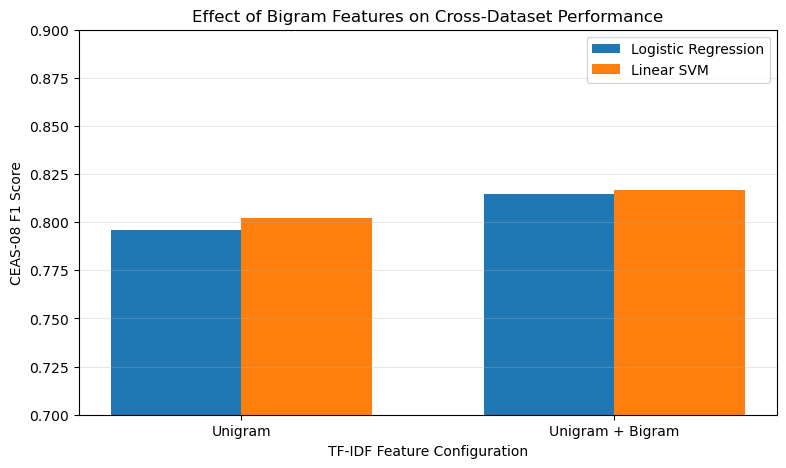

In [23]:
plt.figure(figsize=(9, 5))

x = np.arange(2)
width = 0.35

lr_values = [
    lr_uni_ceas_f1,
    lr_bi_ceas_f1
]

svm_values = [
    svm_uni_ceas_f1,
    svm_bi_ceas_f1
]

plt.bar(
    x - width / 2,
    lr_values,
    width,
    label="Logistic Regression"
)

plt.bar(
    x + width / 2,
    svm_values,
    width,
    label="Linear SVM"
)

plt.xticks(
    x,
    [
        "Unigram",
        "Unigram + Bigram"
    ]
)

plt.ylabel("CEAS-08 F1 Score")
plt.xlabel("TF-IDF Feature Configuration")
plt.title(
    "Effect of Bigram Features on Cross-Dataset Performance"
)

plt.ylim(0.7, 0.9)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [24]:
lr_ceas_improvement = (
    lr_bi_ceas_f1 -
    lr_uni_ceas_f1
)

svm_ceas_improvement = (
    svm_bi_ceas_f1 -
    svm_uni_ceas_f1
)

print(
    f"Logistic Regression CEAS-08 F1 improvement: "
    f"{lr_ceas_improvement * 100:.2f} percentage points"
)

print(
    f"SVM CEAS-08 F1 improvement: "
    f"{svm_ceas_improvement * 100:.2f} percentage points"
)

Logistic Regression CEAS-08 F1 improvement: 1.86 percentage points
SVM CEAS-08 F1 improvement: 1.49 percentage points


In [25]:
ablation_display.to_csv(
    "tfidf_ablation_results.csv",
    index=False
)

print("TF-IDF ablation results saved successfully.")

TF-IDF ablation results saved successfully.
